# exploration du sample



but du projet : prédire l'elo d'un joueur avec une seule de ses parties (parties de 3 min sur lichess).

ici on repart de zéro avec sample_10k et on regarde à chaque étape pourquoi on le fait, ce qu'on voit et si c'est un bon choix.

on utilise **jamais** l'elo de l'adversaire ni le rating_diff comme feature, sinon c'est de la triche.

In [1]:
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from utils.pgn import parse_moves

pd.set_option("display.max_columns", 30)

## 1. les données

In [2]:
df_brut = pd.read_parquet("../../Data/sample_10k.parquet")
df_brut.shape

(10000, 22)

In [3]:
df_brut.head()

,Event,Site,Date,Round,White,Black,Result,UTCDate,UTCTime,WhiteElo,BlackElo,WhiteRatingDiff,BlackRatingDiff,ECO,Opening,TimeControl,Termination,Movetext,WhiteTitle,BlackTitle,moves,n_moves
0,Rated Bullet game,https://lichess.org/bcRJNu4b,2026.09.01,-,Mycoba,Sentenced222,0-1,2026.09.01,00:00:20,1058,1029,-7.0,11.0,B21,Sicilian Defense: Smith-Morra Gambit,120+1,Normal,1. e4 { [%clk 0:02:00] } 1... c5 { [%clk 0:02:...,NaN,NaN,"[e4, c5, d4, cxd4, Qxd4, Nc6, Qd1, Nf6, Nc3, d...",86
1,Rated Bullet game,https://lichess.org/vca9O6Eb,2026.09.01,-,VANDO1975,JollyJumper16,1-0,2026.09.01,00:00:20,896,943,6.0,-6.0,C40,Elephant Gambit,120+1,Time forfeit,1. e4 { [%clk 0:02:00] } 1... e5 { [%clk 0:02:...,NaN,NaN,"[e4, e5, Nf3, d5, exd5, c6, dxc6, Bc5, cxb7, B...",39
2,Rated Bullet game,https://lichess.org/GuMnThlQ,2026.09.01,-,LycanthropicLichen,bco33,0-1,2026.09.01,00:00:20,1542,1554,-8.0,6.0,D31,Queen's Gambit Declined: Queen's Knight Variation,120+1,Time forfeit,1. d4 { [%clk 0:02:00] } 1... e6 { [%clk 0:02:...,NaN,NaN,"[d4, e6, c4, d5, Nc3, h6, Nf3, Nf6, Bf4, Bd6, ...",44
3,Rated Bullet game,https://lichess.org/mQMQpBqI,2026.09.01,-,deeperbluek,larryswanson,0-1,2026.09.01,00:00:20,852,880,-6.0,5.0,C34,King's Gambit Accepted: King's Knight's Gambit,120+1,Time forfeit,1. e4 { [%eval 0.18] [%clk 0:02:00] } 1... e5 ...,NaN,NaN,"[e4, e5, f4?!, exf4, Nf3, Qe7?!, Bc4?!, Nf6, d...",42
4,Rated Bullet game,https://lichess.org/iaY9JqLW,2026.09.01,-,Skyylxne,leminlim3,0-1,2026.09.01,00:00:20,1149,1216,-87.0,8.0,A05,Zukertort Opening,120+1,Time forfeit,1. Nf3 { [%clk 0:02:00] } 1... Nf6 { [%clk 0:0...,NaN,NaN,"[Nf3, Nf6, g3, Nc6, Bg2, e5, O-O, e4, Nh4, Bc5...",44


In [3]:
df_brut.columns

Index(['Event', 'Site', 'Date', 'Round', 'White', 'Black', 'Result', 'UTCDate',
       'UTCTime', 'WhiteElo', 'BlackElo', 'WhiteRatingDiff', 'BlackRatingDiff',
       'ECO', 'Opening', 'TimeControl', 'Termination', 'Movetext',
       'WhiteTitle', 'BlackTitle', 'moves', 'n_moves'],
      dtype='str')

In [6]:
df_brut.dtypes

Event                  str
Site                   str
Date                   str
Round                  str
White                  str
Black                  str
Result                 str
UTCDate                str
UTCTime                str
WhiteElo             int32
BlackElo             int32
WhiteRatingDiff    float64
BlackRatingDiff    float64
ECO                    str
Opening                str
TimeControl            str
Termination            str
Movetext               str
WhiteTitle             str
BlackTitle             str
moves               object
n_moves             uint32
dtype: object

In [5]:
df_brut.iloc[0]

Event                                              Rated Bullet game
Site                                    https://lichess.org/bcRJNu4b
Date                                                      2026.09.01
Round                                                              -
White                                                         Mycoba
Black                                                   Sentenced222
Result                                                           0-1
UTCDate                                                   2026.09.01
UTCTime                                                     00:00:20
WhiteElo                                                        1058
BlackElo                                                        1029
WhiteRatingDiff                                                 -7.0
BlackRatingDiff                                                 11.0
ECO                                                              B21
Opening                         Si

1 ligne = 1 partie. l'elo à prédire c'est WhiteElo et BlackElo (elo avant la partie).

In [7]:
# heure de début des parties
print(df_brut["UTCTime"].min(), df_brut["UTCTime"].max())

00:00:00 00:08:00


In [8]:
df_brut["UTCDate"].value_counts()

UTCDate
2026.09.01    10000
Name: count, dtype: int64

toutes les parties ont commencé entre 00:00 et 00:08 le 1er septembre. donc c'est 8 min de lichess à minuit UTC, c'est l'équivalent de 2h du matin en France et le soir aux US. 

In [4]:
vides = df_brut.isna().sum()
vides[vides > 0]

WhiteRatingDiff      30
BlackRatingDiff      30
WhiteTitle         9906
BlackTitle         9908
dtype: int64

In [5]:
df_brut[df_brut["WhiteRatingDiff"].isna()][["TimeControl", "Termination", "n_moves"]].head()

,TimeControl,Termination,n_moves
888,600+0,Normal,36
1593,300+0,Time forfeit,48
2322,600+0,Normal,15
2450,60+0,Normal,33
2609,600+0,Normal,71


les titres sont presque tout le temps vides, normal la plupart des joueurs n'ont pas de titre

In [12]:
df_brut["TimeControl"].value_counts().head(10)

TimeControl
60+0     2705
180+0    2027
600+0    1203
300+0    1195
180+2     856
120+1     584
300+3     478
600+5     217
30+0      100
15+0       75
Name: count, dtype: int64

In [11]:
df_brut["Event"].value_counts().head(8)

Event
Rated Blitz game                                                   4111
Rated Bullet game                                                  3356
Rated Rapid game                                                   1451
Rated Bullet tournament https://lichess.org/tournament/NlIqQ44i     143
Rated Blitz tournament https://lichess.org/tournament/8CW5T93L      140
Rated UltraBullet game                                               75
Rated Bullet tournament https://lichess.org/tournament/9cDSay7Y      60
Rated Classical game                                                 51
Name: count, dtype: int64

In [ ]:
df_brut.describe()

le plus joué est le bullet 1 min (60+0). nous on garde le 3 min (180+0 et 180+2) en bullet on joue surtout au réflexe, en 3 min on a **le temps de réfléchir**.

par contre en gardant 180+0 et 180+2 ensemble on mélange deux façons de gérer son temps (2s de bonus par coup en 180+2) **à surveiller**

In [6]:
df = df_brut[df_brut["TimeControl"].isin(["180+0", "180+2"])]
df.shape

(2883, 22)

In [7]:
df["TimeControl"].value_counts()

TimeControl
180+0    2027
180+2     856
Name: count, dtype: int64

In [15]:
df.head(2)

,Event,Site,Date,Round,White,Black,Result,UTCDate,UTCTime,WhiteElo,BlackElo,WhiteRatingDiff,BlackRatingDiff,ECO,Opening,TimeControl,Termination,Movetext,WhiteTitle,BlackTitle,moves,n_moves
13,Rated Blitz game,https://lichess.org/IMOSvErG,2026.09.01,-,DOMI60FR,Holizox,1/2-1/2,2026.09.01,00:00:20,1735,1664,-2.0,2.0,D08,Queen's Gambit Declined: Albin Countergambit,180+2,Normal,1. d4 { [%clk 0:03:00] } 1... d5 { [%clk 0:03:...,NaN,NaN,"[d4, d5, c4, e5, cxd5, exd4, Qxd4, Nf6, e4, b6...",99
42,Rated Blitz game,https://lichess.org/bs18a5LO,2026.09.01,-,Q8KSA,IRS007,1-0,2026.09.01,00:00:22,1991,2045,7.0,-7.0,C42,Petrov's Defense: Three Knights Game,180+0,Normal,1. e4 { [%clk 0:03:00] } 1... e5 { [%clk 0:03:...,NaN,NaN,"[e4, e5, Nf3, Nf6, Nc3, Bb4, d3, d5, exd5, Qxd...",85


## 3. les coups

In [16]:
df["Movetext"].iloc[0][:160]

'1. d4 { [%clk 0:03:00] } 1... d5 { [%clk 0:03:00] } 2. c4 { [%clk 0:03:01] } 2... e5 { [%clk 0:02:59] } 3. cxd5 { [%clk 0:03:01] } 3... exd4 { [%clk 0:02:59] } '

In [17]:
df["Movetext"].iloc[1][:300]

'1. e4 { [%clk 0:03:00] } 1... e5 { [%clk 0:03:00] } 2. Nf3 { [%clk 0:02:59] } 2... Nf6 { [%clk 0:02:59] } 3. Nc3 { [%clk 0:02:59] } 3... Bb4 { [%clk 0:02:58] } 4. d3 { [%clk 0:02:55] } 4... d5 { [%clk 0:02:57] } 5. exd5 { [%clk 0:02:53] } 5... Qxd5 { [%clk 0:02:56] } 6. Bd2 { [%clk 0:02:52] } 6... B'

'1.' c'est le coup des blancs et '1...' celui des noirs. 
clk c'est le temps qui reste au joueur après son coup. 
(pas toujours) eval si l'ordinateur a analysé la partie.

tout est collé dans un seul texte donc on utilise "parse_moves" de Yann pour le découper. elle est en polars donc on passe en polars et on revient en pandas.

In [8]:
df = df.drop(columns=["moves", "n_moves"])

In [9]:
df = parse_moves(pl.from_pandas(df)).to_pandas()
df.shape

(2883, 21)

In [10]:
df.columns

Index(['Event', 'Site', 'Date', 'Round', 'White', 'Black', 'Result', 'UTCDate',
       'UTCTime', 'WhiteElo', 'BlackElo', 'WhiteRatingDiff', 'BlackRatingDiff',
       'ECO', 'Opening', 'TimeControl', 'Termination', 'WhiteTitle',
       'BlackTitle', 'moves', 'n_moves'],
      dtype='str')

In [11]:
df["moves"][0][:3]

array([{'san': 'd4', 'clk': '0:03:00', 'eval': None},
       {'san': 'd5', 'clk': '0:03:00', 'eval': None},
       {'san': 'c4', 'clk': '0:03:01', 'eval': None}], dtype=object)

In [21]:
df["moves"][0][-3:]

array([{'san': 'Kd4', 'clk': '0:01:27', 'eval': None},
       {'san': 'Kc6', 'clk': '0:00:54', 'eval': None},
       {'san': 'Kc4', 'clk': '0:01:28', 'eval': None}], dtype=object)

In [12]:
len(df["moves"][0]), df["n_moves"][0]

(99, np.uint32(99))

In [13]:
#n_moves = nombre de demi coups (un coup blanc ou un coup noir)
df["n_moves"].describe()

count    2883.000000
mean       70.548387
std        31.974953
min         0.000000
25%        48.000000
50%        66.000000
75%        90.000000
max       196.000000
Name: n_moves, dtype: float64

In [14]:
df[df["n_moves"] == 0][["White", "Black", "Termination", "Result"]]

,White,Black,Termination,Result
38,rocoide,luxaflex,Abandoned,0-1
228,bigpawn63,Samuel_Matematico,Abandoned,0-1
1159,BryanManayay_USAT,GheraldyQuispe_USAT,Time forfeit,0-1
1649,gmpinguinito,jhoaan4459,Abandoned,0-1
1891,Ammo511,callmeChinaski,Abandoned,0-1


une partie fait en moyenne 66 demi coups. mais le min c'est 0, y'a des parties sans aucun coup, à regarder.

## nettoyage des parties



on cherche les parties qui ne disent rien sur le niveau des joueurs. 
on fait des masques (True/False) et on supprime tout à la fin.


### les bots


In [24]:
pd.concat([df["WhiteTitle"], df["BlackTitle"]]).value_counts()

BOT    31
FM     16
NM      7
CM      6
IM      2
Name: count, dtype: int64

In [15]:
bot = (df["WhiteTitle"] == "BOT") | (df["BlackTitle"] == "BOT")
bot.sum()

np.int64(18)

In [26]:
df[bot][["White", "WhiteElo", "WhiteTitle", "Black", "BlackElo", "BlackTitle"]].head()

,White,WhiteElo,WhiteTitle,Black,BlackElo,BlackTitle
17,eigenmann-chess,2797,BOT,Odiodin_ansf,2842,BOT
490,ChessatronBot,2477,BOT,ZobristHaescher,2472,BOT
507,prokopakop,2589,BOT,maia3_600,2300,BOT
542,LegoChess98,1993,BOT,notropis,1745,BOT
692,Hyperopic,2016,BOT,Mithandros,2018,BOT


18 parties avec un bot. on enlève toute la partie, un joueur joue différement face à un bot... les autres titres sont de vrais joueurs.



### les fins bizarres

In [17]:
df["Termination"].value_counts()

Termination
Normal                   2076
Time forfeit              792
Abandoned                  14
Insufficient material       1
Name: count, dtype: int64

In [18]:
df[df["Termination"] == "Abandoned"]["n_moves"].value_counts()

n_moves
1    10
0     4
Name: count, dtype: int64

les parties "Abandoned" ont 0 ou 1 coup, ce sont des parties qui ne sont pas jouée qu'on retire.

In [16]:
mauvaise_fin = df["Termination"].isin(["Abandoned"])
mauvaise_fin.sum()

np.int64(14)

### les joueurs absents



idée : un joueur qui part en pleine partie perd au temps, sa pendule descend jusqu'à 0. mais perdre au temps ça arrive aussi à des joueurs normaux. il faut donc réusiir à différencier les deux:

la différence c'est qu'un joueur normal joue jusqu'au bout, donc à son dernier coup il lui reste quelque chose comme 2s. un absent a beaucoup de temps quand il arrête

le perdant au temps c'est celui qui devait jouer, donc son dernier coup c'est l'avant dernier de la partie ([-2]), ce n'est pas une règle infaillible mais c'est difficile de trouver mieux...

In [19]:
au_temps = df["Termination"] == "Time forfeit"

In [20]:
temps_restant = pd.to_timedelta(df["moves"].str[-2].str["clk"]).dt.total_seconds()

In [21]:
temps_restant.head()

0     54.0
1     13.0
2    169.0
3      8.0
4     71.0
Name: moves, dtype: float64

In [22]:
df["moves"][2][-2:]

array([{'san': 'h5', 'clk': '0:02:49', 'eval': None},
       {'san': 'Nf5', 'clk': '0:02:50', 'eval': None}], dtype=object)

In [24]:
temps_restant[au_temps].isna().sum()

np.int64(2)

In [23]:
temps_restant[au_temps].describe(percentiles=[0.5, 0.75, 0.9, 0.95])

count    790.000000
mean      13.703797
std       35.733854
min        0.000000
50%        2.000000
75%        5.000000
90%       29.000000
95%       99.550000
max      186.000000
Name: moves, dtype: float64

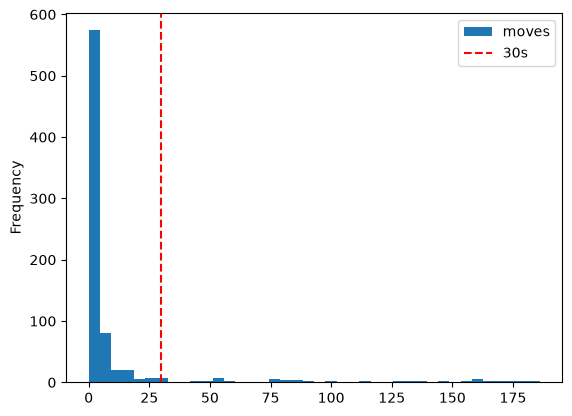

In [27]:
temps_restant[au_temps].plot.hist(bins=40)
plt.axvline(30, color="red", ls="--", label="30s")
plt.legend()
plt.show()

une grosse partie des perdants au temps avaient 2s ou moins, mais on a beaucoup de lignes avec des joueurs qui ont +1min

In [26]:
for seuil in [10, 20, 30, 60]:
    print(seuil, (au_temps & (temps_restant > seuil)).sum())

10 127
20 93
30 76
60 61


je prends 30s, la plupart des perdants au temps sont en dessous on peut dire que ce sont des valeurs aberrantes.

entre 10 et 30s on sait pas trop, quelqu'un peut réfléchir 20s et perdre au temps. avec 30s on va préfèrer garder des cas douteux

In [28]:
absent = au_temps & (temps_restant > 30)
absent.sum()

np.int64(76)

In [32]:
df[absent][["n_moves", "Termination", "Result", "TimeControl"]].head()

,n_moves,Termination,Result,TimeControl
22,48,Time forfeit,0-1,180+0
24,40,Time forfeit,0-1,180+0
93,86,Time forfeit,0-1,180+0
202,26,Time forfeit,0-1,180+2
302,20,Time forfeit,0-1,180+0


### comparaison avec la règle de moins de 20 demi copups

In [30]:
court = df["n_moves"] < 20
pd.crosstab(absent, court)

n_moves,False,True
row_0,,
False,2718,89
True,65,11


In [31]:
# les parties courtes qui sont pas des absents
df[court & ~absent]["Termination"].value_counts()

Termination
Normal          73
Abandoned       14
Time forfeit     2
Name: count, dtype: int64

65 absents ont plus de 20 demi coups donc la règle du groupe les rate... dans l'autre sens elle supprime 89 parties courtes qui ne sont pas forcément des absents, la plupart finissent "Normal" ce sont donc des vraies parrties.

d'autre part, une partie de 8 demi coups ne donne pas beaucoup d'info, on la garde mais les features ne seront pas fiables pour ces joueurs.


### on nettoie

In [33]:
pipeline_retirer = bot | mauvaise_fin | absent
pipeline_retirer.sum()

np.int64(106)

In [34]:
df = df.drop(df[pipeline_retirer].index)
df.shape

(2777, 21)

il en reste 2777.

## une ligne par joueur



In [35]:
df["game_id"] = df["Site"].str[-8:]
df["game_id"].is_unique

True

In [36]:
blancs = pd.DataFrame({
    "game_id": df["game_id"],
    "joueur": df["White"],
    "couleur": "blanc",
    "elo": df["WhiteElo"],
    "rating_diff": df["WhiteRatingDiff"],
    "cadence": df["TimeControl"],
    "event": df["Event"],
    "resultat": df["Result"],
    "termination": df["Termination"],
    "eco": df["ECO"],
    "coups": df["moves"].str[0::2],
})

In [38]:
noirs = pd.DataFrame({
    "game_id": df["game_id"],
    "joueur": df["Black"],
    "couleur": "noir",
    "elo": df["BlackElo"],
    "rating_diff": df["BlackRatingDiff"],
    "cadence": df["TimeControl"],
    "event": df["Event"],
    "resultat": df["Result"],
    "termination": df["Termination"],
    "eco": df["ECO"],
    "coups": df["moves"].str[1::2],
})

In [39]:
joueurs = pd.concat([blancs, noirs], ignore_index=True)
joueurs.shape

(5554, 11)

In [37]:
blancs.head(3)

,game_id,joueur,couleur,elo,rating_diff,cadence,event,resultat,termination,eco,coups
0,IMOSvErG,DOMI60FR,blanc,1735,-2.0,180+2,Rated Blitz game,1/2-1/2,Normal,D08,"[{'san': 'd4', 'clk': '0:03:00', 'eval': None}..."
1,bs18a5LO,Q8KSA,blanc,1991,7.0,180+0,Rated Blitz game,1-0,Normal,C42,"[{'san': 'e4', 'clk': '0:03:00', 'eval': None}..."
2,YXYiz29z,MiltonMorales,blanc,2224,-6.0,180+0,Rated Blitz game,0-1,Normal,B23,"[{'san': 'e4', 'clk': '0:03:00', 'eval': None}..."


In [40]:
joueurs.head()

,game_id,joueur,couleur,elo,rating_diff,cadence,event,resultat,termination,eco,coups
0,IMOSvErG,DOMI60FR,blanc,1735,-2.0,180+2,Rated Blitz game,1/2-1/2,Normal,D08,"[{'san': 'd4', 'clk': '0:03:00', 'eval': None}..."
1,bs18a5LO,Q8KSA,blanc,1991,7.0,180+0,Rated Blitz game,1-0,Normal,C42,"[{'san': 'e4', 'clk': '0:03:00', 'eval': None}..."
2,YXYiz29z,MiltonMorales,blanc,2224,-6.0,180+0,Rated Blitz game,0-1,Normal,B23,"[{'san': 'e4', 'clk': '0:03:00', 'eval': None}..."
3,nnqUdpEC,nallek,blanc,1744,4.0,180+0,Rated Blitz game,1-0,Time forfeit,A00,"[{'san': 'c3', 'clk': '0:03:00', 'eval': None}..."
4,kXbkGSNm,evgeniy_duk,blanc,1557,-5.0,180+2,Rated Blitz game,0-1,Normal,D40,"[{'san': 'd4', 'clk': '0:03:00', 'eval': None}..."


In [41]:
joueurs["couleur"].value_counts()

couleur
blanc    2777
noir     2777
Name: count, dtype: int64

In [42]:
# même partie, chacun ses coups
print(joueurs["coups"][0][0]["san"], joueurs["coups"][0][1]["san"])
print(joueurs["coups"][2777][0]["san"], joueurs["coups"][2777][1]["san"])

d4 c4
d5 e5


5554 lignes = 2777 parties x 2.



### l'elo de l'adversaire

In [43]:
print(df["WhiteElo"].corr(df["BlackElo"]))

0.9484206468043775


In [44]:
(df["WhiteElo"] - df["BlackElo"]).abs().describe()

count    2777.000000
mean       58.718041
std        98.358912
min         0.000000
25%        12.000000
50%        31.000000
75%        66.000000
max      1211.000000
dtype: float64

corrélation de 0.95 lichess fait jouer des joueurs du même niveau. donc si on donnait l'elo de l'adversaire au modèle il trouverait presque direct, feature leakage... pareil pour rating_diff qui est calculé après la partie.

## l'elo

In [45]:
joueurs["elo"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])

count    5554.000000
mean     1679.908174
std       356.613170
min       651.000000
1%        866.000000
25%      1436.000000
50%      1705.500000
75%      1938.000000
99%      2433.940000
max      2807.000000
Name: elo, dtype: float64

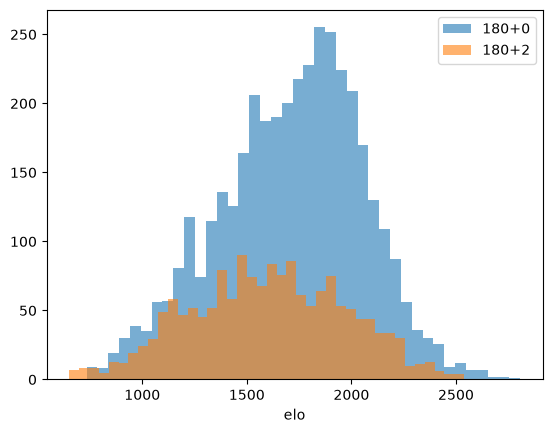

In [46]:
plt.hist(joueurs[joueurs["cadence"] == "180+0"]["elo"], bins=40, alpha=0.6, label="180+0")
plt.hist(joueurs[joueurs["cadence"] == "180+2"]["elo"], bins=40, alpha=0.6, label="180+2")
plt.xlabel("elo")
plt.legend()
plt.show()

In [47]:
joueurs.groupby("cadence")["elo"].agg(["count", "mean", "median", "std"]).round()

,count,mean,median,std
cadence,,,,
180+0,3920,1712.0,1746.0,345.0
180+2,1634,1602.0,1609.0,371.0


forme de cloche, médiane vers 1705, écart type 357. 98% des joueurs entre 866 et 2434.

en 180+2 l'elo est 110 points plus bas en moyenne, donc la cadence donne déjà une info sur l'elo, faut la garder comme feature.


### baseline
le modèle le plus bête : on prédit la médiane pour tout le monde et on regarde l'erreur moyenne (MAE).

In [48]:
mediane = joueurs["elo"].median()
mae = (joueurs["elo"] - mediane).abs().mean()
print(mediane, mae)

1705.5 290.0417716960749


In [49]:
(joueurs["elo"] - joueurs["elo"].mean()).abs().mean()

np.float64(290.6810603692116)

## elo provisoires



un nouveau compte commence à 1500 et son elo bouge beaucoup au début, c'est pas une target fiable...

In [50]:
ecart_elo = joueurs["rating_diff"].abs()
ecart_elo.describe(percentiles=[0.5, 0.9, 0.95, 0.99])

count    5548.000000
mean        6.894917
std        15.202804
min         0.000000
50%         6.000000
90%         8.000000
95%        10.000000
99%        35.000000
max       607.000000
Name: rating_diff, dtype: float64

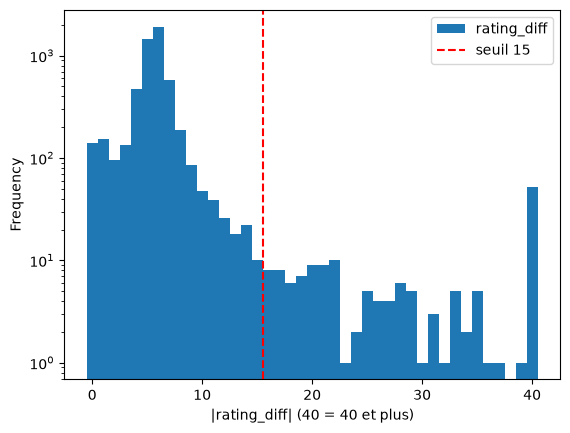

In [51]:
ecart_elo.clip(upper=40).plot.hist(bins=41, range=(-0.5, 40.5), log=True)
plt.axvline(15.5, color="red", ls="--", label="seuil 15")
plt.xlabel("|rating_diff| (40 = 40 et plus)")
plt.legend()
plt.show()

In [55]:
# elo moyen selon l'écart
tranche_ecart = pd.cut(ecart_elo, [-1, 5, 8, 10, 15, 20, 40, 1000])
joueurs.groupby(tranche_ecart, observed=True)["elo"].agg(["count", "mean"]).round()

,count,mean
rating_diff,,
"(-1, 5]",2454,1708.0
"(5, 8]",2690,1675.0
"(8, 10]",133,1641.0
"(10, 15]",115,1540.0
"(15, 20]",38,1513.0
"(20, 40]",67,1458.0
"(40, 1000]",51,1465.0


In [53]:
for seuil in [10, 15, 20, 30]:
    print(seuil, (ecart_elo > seuil).sum())

10 271
15 156
20 118
30 71


gros pic à 5-6-7, normal. et quand l'écart dépasse 10 l'elo moyen tombe vers 1500, donc on peut conculre que ce sont des nouveaux copmptes.


In [54]:
joueurs[ecart_elo > 100][["joueur", "elo", "rating_diff", "resultat"]].head()

,joueur,elo,rating_diff,resultat
8,AkooMY,1732,139.0,1-0
227,Azizgh-7,1500,-265.0,0-1
315,Extraterrestialbeing,1500,-268.0,0-1
909,Saritina,1216,-163.0,0-1
1112,DiegoCoello_USAT,1254,143.0,1/2-1/2


In [56]:
provisoire = joueurs["rating_diff"].abs() > 15
joueurs = joueurs.drop(joueurs[provisoire].index)
joueurs = joueurs.dropna(subset=["rating_diff"])
joueurs.shape

(5392, 11)

## même joueur plusieurs fois

In [57]:
n = joueurs["joueur"].value_counts()
print(len(n), (n == 1).sum(), n.max())

4059 2867 4


In [58]:
n.head()

joueur
omarhosny01          4
Chess-Guru-7         4
truckdrivermonkey    4
Erizo555             4
Imoral_5             4
Name: count, dtype: int64

In [59]:
# l'elo d'un même joueur bouge entre ses parties ?
par_joueur = joueurs.groupby("joueur")["elo"].agg(["count", "std"])
par_joueur[par_joueur["count"] > 1]["std"].describe()

count    1192.000000
mean        4.074086
std         1.877431
min         0.000000
25%         3.535534
50%         4.242641
75%         4.242641
max        44.547727
Name: std, dtype: float64

In [60]:
joueurs[joueurs["joueur"] == n.index[0]][["joueur", "elo", "cadence", "resultat"]]

,joueur,elo,cadence,resultat
423,omarhosny01,1569,180+0,1-0
2513,omarhosny01,1587,180+0,1-0
3518,omarhosny01,1575,180+0,0-1
3984,omarhosny01,1582,180+0,0-1


4059 joueurs, la plupart 1 seule partie et pour un même joueur l'elo bouge que de 4 points environ.

donc quand on fera train/test il faudra couper par joueur, sinon le modèle reconnait le joueur au lieu d'apprendre. 

## la pendule



clk c'est le temps qui reste, nous on veut le temps passé sur chaque coup. on déplie les coups et chaque ligne garde le numéro de son joueur donc après on peut regrouper par joueur.

In [61]:
coups = joueurs["coups"].explode()

In [63]:
clk = pd.to_timedelta(coups.str["clk"]).dt.total_seconds()
clk.head()

0    180.0
0    181.0
0    181.0
0    181.0
0    180.0
Name: coups, dtype: float64

In [62]:
coups.head()

0      {'san': 'd4', 'clk': '0:03:00', 'eval': None}
0      {'san': 'c4', 'clk': '0:03:01', 'eval': None}
0    {'san': 'cxd5', 'clk': '0:03:01', 'eval': None}
0    {'san': 'Qxd4', 'clk': '0:03:01', 'eval': None}
0      {'san': 'e4', 'clk': '0:03:00', 'eval': None}
Name: coups, dtype: object

In [64]:
len(coups), len(clk)

(193512, 193512)

### berserk



en tournoi on peut berserk : on coupe son temps en 2 (1:30 au lieu de 3:00) pour gagner plus de points. leur rythme n'est pas comparable.

In [65]:
debut = clk.groupby(level=0).first()
debut.value_counts().head(8)

coups
180.0    5275
90.0      113
82.0        1
195.0       1
175.0       1
176.0       1
Name: count, dtype: int64

In [66]:
berserk = debut < 170
berserk.sum()

np.int64(114)

In [67]:
debut[debut < 170].head()

79     90.0
80     90.0
84     90.0
199    90.0
210    90.0
Name: coups, dtype: float64

In [68]:
# c'est bien des tournois ?
joueurs[berserk]["event"].str.contains("tournament").sum()

np.int64(113)

In [69]:
joueurs[berserk]["event"].value_counts().head()

event
Rated Blitz tournament https://lichess.org/tournament/8CW5T93L    49
Rated Blitz tournament https://lichess.org/tournament/Ho2mQSN5    21
Rated Blitz tournament https://lichess.org/tournament/K60f00G8    13
Rated Blitz tournament https://lichess.org/tournament/9DzKmQVT    10
Rated Blitz tournament https://lichess.org/tournament/O1UtmwXW    10
Name: count, dtype: int64

In [70]:
print(joueurs[berserk]["elo"].mean())
print(joueurs["elo"].mean())

1906.9035087719299
1686.0124258160238


114 berserk dont 113 en tournoi, on les supprime.

on enlève surtout les bons joueurs en faisqnt ça : 1906 elo en moyenne.



### temps par coup



temps passé = temps avant - temps après + incrément. en 180+2 lichess rajoute 2s après chaque coup donc faut les remettre.

In [71]:
inc = joueurs["cadence"].str.split("+").str[1].astype(int)
inc.value_counts()

cadence
0    3828
2    1564
Name: count, dtype: int64

In [72]:
joueurs["cadence"].str.split("+").head()

0    [180, 2]
1    [180, 0]
2    [180, 0]
3    [180, 0]
4    [180, 2]
Name: cadence, dtype: object

In [73]:
ecart = clk.groupby(level=0).diff()

In [74]:
temps = -ecart + inc

In [75]:
pd.DataFrame({"clk": clk.head(6), "ecart": ecart.head(6), "temps": temps.head(6)})

,clk,ecart,temps
0,180.0,NaN,NaN
0,181.0,1.0,1.0
0,181.0,0.0,2.0
0,181.0,0.0,2.0
0,180.0,-1.0,3.0
0,177.0,-3.0,5.0


In [76]:
temps.isna().sum(), joueurs.shape[0]

(np.int64(5392), 5392)

In [77]:
temps.describe(percentiles=[0.5, 0.9, 0.99])

count    188120.000000
mean          3.852764
std           5.075160
min        -285.000000
50%           2.000000
90%           9.000000
99%          24.000000
max         130.000000
dtype: float64

### temps ajouté

médiane 2s par coup, mais le min c'est -285s. un temps négatif c'est impossible, ça veut dire que l'adversaire a donné 15s.

In [78]:
print(temps[temps < 0].tolist())

[-1.0, -30.0, -285.0, -185.0]


In [79]:
temps_ajoute = (temps < 0).groupby(level=0).any()
temps_ajoute.sum()

np.int64(3)

In [80]:
joueurs[temps_ajoute][["joueur", "elo", "cadence", "event"]]

,joueur,elo,cadence,event
451,coachpavlo2003,2316,180+2,Rated Blitz game
1397,nanouce,1208,180+0,Rated Blitz game
2913,motorcyclemitch,1706,180+2,Rated Blitz game


3 joueurs, on les enlève.



### pas assez de coups



pour avoir un temps il faut au moins 2 coups (le 1er a pas de temps).

In [81]:
n_coups = joueurs["coups"].str.len()
peu_de_coups = n_coups < 2
peu_de_coups.sum()

np.int64(2)

In [82]:
joueurs[peu_de_coups][["joueur", "elo", "termination", "resultat"]]

,joueur,elo,termination,resultat
1339,upzjxj,955,Normal,1-0
4116,QuayanaCallugta,1033,Normal,1-0


In [83]:
joueurs_retirer = berserk | temps_ajoute | peu_de_coups
joueurs = joueurs.drop(joueurs[joueurs_retirer].index)
joueurs.shape

(5273, 11)

reste 5273 joueurs. comme on a enlevé des joueurs on recalcule tout. num est le numéro du coup du joueur (0 = son 1er coup)

In [84]:
coups = joueurs["coups"].explode()
clk = pd.to_timedelta(coups.str["clk"]).dt.total_seconds()
inc = joueurs["cadence"].str.split("+").str[1].astype(int)

In [85]:
ecart = clk.groupby(level=0).diff()
temps = -ecart + inc

In [86]:
num = coups.groupby(level=0).cumcount()

In [88]:
temps.min()

np.float64(0.0)

In [87]:
num.head(12)

0     0
0     1
0     2
0     3
0     4
0     5
0     6
0     7
0     8
0     9
0    10
0    11
dtype: int64

plus de temps négatif, c'est bon.

## features de pendule



pour chaque joueur on résume ses temps en quelques chiffres:

n_coups : les forts font des parties plus longues ?

t_ouverture (coups 1 à 10) : les forts connaissent leurs ouvertures par coeur.

t_milieu (11 à 25) : c'est là qu'on réfléchit.

t_finale (26 et +).

pct_rapides : % de coups en 1s ou moins.

t_max : la plus longue réflexion.

temps_fin : temps restant à la fin.

In [89]:
joueurs["n_coups"] = coups.groupby(level=0).size()
joueurs["t_moyen"] = temps.groupby(level=0).mean()

In [90]:
joueurs["t_ouverture"] = temps[num < 10].groupby(level=0).mean()

In [91]:
joueurs["t_milieu"] = temps[(num >= 10) & (num < 25)].groupby(level=0).mean()
joueurs["t_finale"] = temps[num >= 25].groupby(level=0).mean()

In [92]:
joueurs[["n_coups", "t_moyen", "t_ouverture", "t_milieu", "t_finale"]].head()

,n_coups,t_moyen,t_ouverture,t_milieu,t_finale
0,50,3.877551,2.888889,4.000000,4.160000
1,43,3.642857,1.444444,6.733333,2.166667
2,14,0.846154,0.777778,1.000000,NaN
3,33,5.093750,3.666667,6.466667,4.125000
4,35,5.205882,5.333333,6.000000,3.900000


In [93]:
# dropna pour pas compter le 1er coup
rapide = temps.dropna() <= 1
joueurs["pct_rapides"] = rapide.groupby(level=0).mean() * 100

In [94]:
joueurs["t_max"] = temps.groupby(level=0).max()
joueurs["temps_fin"] = clk.groupby(level=0).last()

In [95]:
features_temps = ["n_coups", "t_moyen", "t_ouverture", "t_milieu", "t_finale", "pct_rapides", "t_max", "temps_fin"]
joueurs[features_temps].describe().round(2)

,n_coups,t_moyen,t_ouverture,t_milieu,t_finale,pct_rapides,t_max,temps_fin
count,5273.00,5273.00,5273.00,5114.00,3852.00,5273.00,5273.00,5273.00
mean,35.85,4.06,2.53,5.42,3.96,32.83,19.77,63.78
std,15.61,1.73,1.76,2.63,2.64,15.66,12.48,51.42
min,2.00,0.00,0.00,0.50,0.00,0.00,0.00,0.00
25%,25.00,2.85,1.33,3.60,2.40,21.62,11.00,16.00
50%,34.00,3.76,2.00,4.87,3.36,31.58,17.00,56.00
75%,46.00,4.96,3.11,6.80,4.79,42.86,25.00,103.00
max,98.00,19.78,19.78,35.50,46.00,100.00,130.00,195.00


In [96]:
joueurs.sort_values("t_ouverture", ascending=False)[["joueur", "elo", "cadence", "n_coups", "t_ouverture"]].head()

,joueur,elo,cadence,n_coups,t_ouverture
4965,mattas87,1295,180+2,10,19.777778
4773,Frakh,2035,180+2,37,16.222222
5343,Michtiti,1340,180+2,19,14.888889
391,Nouzdov,2028,180+2,15,14.333333
2204,Rene_11,1691,180+2,67,13.888889


2.5s par coup dans l'ouverture, 5.4s au milieu, 4s en finale. le milieu c'est bien là qu'on réfléchit le plus. un tiers des coups sont joués en 1s ou moins.



### lien avec l'elo



**spearman** : est ce que les 2 montent ou descendent ensemble (même si c'est pas une ligne droite). 1 ou -1 = lien fort, 0 = rien.

In [100]:
corr = joueurs[features_temps + ["elo"]].corr(method="spearman")["elo"]
corr.drop("elo").sort_values()

t_ouverture   -0.310345
temps_fin     -0.123161
t_moyen       -0.107358
t_milieu      -0.056499
t_finale      -0.022460
t_max          0.084633
n_coups        0.185959
pct_rapides    0.265823
Name: elo, dtype: float64

In [98]:
# moyenne par tranche de 200 elo
tranche = (joueurs["elo"] // 200 * 200).clip(800, 2400)
par_tranche = joueurs.groupby(tranche)[["t_ouverture", "t_milieu", "t_finale", "pct_rapides", "n_coups"]].mean()
par_tranche["nb"] = joueurs.groupby(tranche).size()
par_tranche.round(2)

,t_ouverture,t_milieu,t_finale,pct_rapides,n_coups,nb
elo,,,,,,
800,4.05,6.50,3.90,21.53,29.09,175
1000,3.58,5.60,4.00,24.97,30.21,379
1200,3.01,5.62,4.28,28.33,32.78,619
1400,2.63,5.42,3.85,32.41,35.48,897
1600,2.40,5.29,3.89,33.59,35.69,1087
1800,2.10,5.28,3.94,35.17,38.00,1109
2000,2.11,5.38,4.07,36.42,38.88,681
2200,2.08,5.39,3.85,38.59,39.51,255
2400,2.16,4.86,3.36,43.86,41.07,71


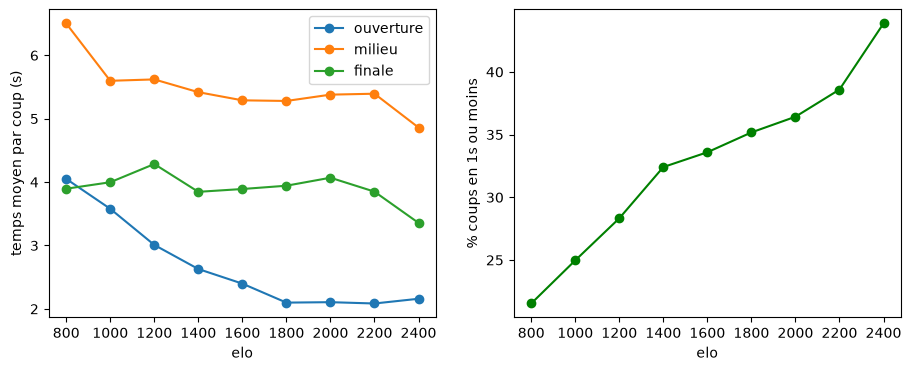

In [102]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(par_tranche.index, par_tranche["t_ouverture"], marker="o", label="ouverture")
ax[0].plot(par_tranche.index, par_tranche["t_milieu"], marker="o", label="milieu")
ax[0].plot(par_tranche.index, par_tranche["t_finale"], marker="o", label="finale")
ax[0].set_xlabel("elo")
ax[0].set_ylabel("temps moyen par coup (s)")
ax[0].legend()

ax[1].plot(par_tranche.index, par_tranche["pct_rapides"], marker="o", color="green")
ax[1].set_xlabel("elo")
ax[1].set_ylabel("% coups en 1s ou moins")

plt.show()

les forts jouent plus vite l’ouverture (4s par coup chez les 800, 2s chez les 1800+) et font plus de coups rapides. **c’est les 2 features les plus liées à l’elo.** par contre au dessus de 1800 t_ouverture ne bouge plus, donc elle sépare surtout les débutants des autres.

le temps au milieu et en finale change presque pas avec le niveau. et le temps moyen sur toute la partie marche moins bien parce qu’il mélange les phases, c’est pour ça qu’on découpe.

## la cadence change le rythme ?

In [101]:
joueurs.groupby("cadence")[["t_ouverture", "t_milieu", "t_finale", "pct_rapides"]].mean().round(2)

,t_ouverture,t_milieu,t_finale,pct_rapides
cadence,,,,
180+0,2.14,4.64,3.43,36.51
180+2,3.45,7.29,5.31,24.06


en 180+2 les joueurs sont plus faibles en moyenne donc pour comparer faut regarder à elo égal.

## les vides

In [103]:
joueurs[features_temps].isna().sum()

n_coups           0
t_moyen           0
t_ouverture       0
t_milieu        159
t_finale       1421
pct_rapides       0
t_max             0
temps_fin         0
dtype: int64

t_milieu vide pour 159 joueurs et t_finale pour 1421 : c'est ceux dont la partie s'est arrêtée avant le coup 11 ou 26. est ce que c'est des joueurs différents ?

In [104]:
finale_vide = joueurs["t_finale"].isna()
joueurs.groupby(finale_vide)[["elo", "n_coups"]].mean().round()

,elo,n_coups
t_finale,,
False,1716.0,42.0
True,1589.0,18.0


In [105]:
joueurs.groupby(finale_vide)["termination"].value_counts(normalize=True).round(2)

t_finale  termination          
False     Normal                   0.67
          Time forfeit             0.33
          Insufficient material    0.00
True      Normal                   0.95
          Time forfeit             0.05
Name: proportion, dtype: float64

ceux qui ont pas de t_finale ont un elo moyen de 1589 contre 1716, parties courtes (18 coups) qui finissent presque toutes "Normal" (mat ou abandon rapide). Le vide est une infoi

supprimer les lignes = virer surtout des faibles, mauvaise idée. mettre 0 = dire qu'il a joué instantanément, faux.

on fait une colonne oui/non pour garder l'info et on remplit avec la médiane de la cadence du joueur qui est neutre.

In [106]:
joueurs["a_milieu"] = joueurs["t_milieu"].notna().astype(int)

In [107]:
mediane_milieu = joueurs.groupby("cadence")["t_milieu"].median()
print(mediane_milieu)

cadence
180+0    4.333333
180+2    7.000000
Name: t_milieu, dtype: float64


In [109]:
# map remplace la cadence de chaque joueur par sa médiane
joueurs["t_milieu"] = joueurs["t_milieu"].fillna(joueurs["cadence"].map(mediane_milieu))

In [108]:
joueurs["cadence"].map(mediane_milieu).head()

0    7.000000
1    4.333333
2    4.333333
3    4.333333
4    7.000000
Name: cadence, dtype: float64

In [110]:
joueurs["a_finale"] = joueurs["t_finale"].notna().astype(int)

In [111]:
mediane_finale = joueurs.groupby("cadence")["t_finale"].median()
joueurs["t_finale"] = joueurs["t_finale"].fillna(joueurs["cadence"].map(mediane_finale))

In [112]:
joueurs[features_temps + ["a_milieu", "a_finale"]].isna().sum()

n_coups        0
t_moyen        0
t_ouverture    0
t_milieu       0
t_finale       0
pct_rapides    0
t_max          0
temps_fin      0
a_milieu       0
a_finale       0
dtype: int64

plus de vides

## normalisation par cadence


on veut que les features veulent dire plus lent ou plus rapide que les autres joueurs de sa cadence

In [113]:
moyenne_cadence = joueurs.groupby("cadence")["t_ouverture"].mean()
print(moyenne_cadence)

cadence
180+0    2.143149
180+2    3.451433
Name: t_ouverture, dtype: float64


In [114]:
joueurs["t_ouverture_centre"] = joueurs["t_ouverture"] - joueurs["cadence"].map(moyenne_cadence)

In [116]:
# moyenne par cadence doit faire 0
joueurs.groupby("cadence")["t_ouverture_centre"].mean().round(4)

cadence
180+0   -0.0
180+2    0.0
Name: t_ouverture_centre, dtype: float64

In [115]:
joueurs[["cadence", "t_ouverture", "t_ouverture_centre"]].head()

,cadence,t_ouverture,t_ouverture_centre
0,180+2,2.888889,-0.562544
1,180+0,1.444444,-0.698705
2,180+0,0.777778,-1.365372
3,180+0,3.666667,1.523517
4,180+2,5.333333,1.881901


standardisation classique

In [117]:
std_cadence = joueurs.groupby("cadence")["t_ouverture"].std()
print(std_cadence)

cadence
180+0    1.380940
180+2    2.188789
Name: t_ouverture, dtype: float64


In [118]:
joueurs["t_ouverture_std"] = joueurs["t_ouverture_centre"] / joueurs["cadence"].map(std_cadence)

In [119]:
# moyenne 0 et écart type 1 dans chaque cadence
joueurs.groupby("cadence")["t_ouverture_std"].agg(["mean", "std"]).round(4)

,mean,std
cadence,,
180+0,-0.0,1.0
180+2,0.0,1.0


In [120]:
# pareil pour les autres
for f in ["t_moyen", "t_milieu", "t_finale", "pct_rapides", "t_max", "temps_fin"]:
    moy = joueurs["cadence"].map(joueurs.groupby("cadence")[f].mean())
    et = joueurs["cadence"].map(joueurs.groupby("cadence")[f].std())
    joueurs[f + "_std"] = (joueurs[f] - moy) / et

In [121]:
joueurs.columns

Index(['game_id', 'joueur', 'couleur', 'elo', 'rating_diff', 'cadence',
       'event', 'resultat', 'termination', 'eco', 'coups', 'n_coups',
       't_moyen', 't_ouverture', 't_milieu', 't_finale', 'pct_rapides',
       't_max', 'temps_fin', 'a_milieu', 'a_finale', 't_ouverture_centre',
       't_ouverture_std', 't_moyen_std', 't_milieu_std', 't_finale_std',
       'pct_rapides_std', 't_max_std', 'temps_fin_std'],
      dtype='str')

In [122]:
avant = joueurs[["t_ouverture", "pct_rapides", "t_milieu", "elo"]].corr(method="spearman")["elo"]
apres = joueurs[["t_ouverture_std", "pct_rapides_std", "t_milieu_std", "elo"]].corr(method="spearman")["elo"]
print(avant.round(3))
print(apres.round(3))

t_ouverture   -0.310
pct_rapides    0.266
t_milieu      -0.062
elo            1.000
Name: elo, dtype: float64
t_ouverture_std   -0.282
pct_rapides_std    0.235
t_milieu_std      -0.003
elo                1.000
Name: elo, dtype: float64


## l'eval

problème : l'eval existe que si quelqu'un a demandé l'analyse de la partie.

l'eval avant mon coup c'est l'eval après le coup de l'adversaire, donc on travaille au niveau de la partie (df) et après on ramène aux joueurs.

In [123]:
demi_coups = df["moves"].explode()
eval_texte = demi_coups.str["eval"]

In [124]:
partie_a_eval = eval_texte.notna().groupby(level=0).any()
print(partie_a_eval.sum(), len(partie_a_eval))

233 2777


In [125]:
eval_texte.dropna().head()

5    0.18
5    0.22
5     0.0
5    0.18
5    0.07
Name: moves, dtype: object

In [126]:
# dans les parties analysées, quelle part des coups a une eval
part = eval_texte.notna().groupby(level=0).mean()
part[partie_a_eval].describe()

count    233.000000
mean       0.995678
std        0.008301
min        0.962963
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: moves, dtype: float64

233 parties sur 2777, mais quand une partie est analysée presque tous ses coups ont une eval.



### qui fait analyser ses parties ?

In [127]:
elo_partie = (df["WhiteElo"] + df["BlackElo"]) / 2
tranche_partie = (elo_partie // 400 * 400).clip(800, 2400)

print((partie_a_eval.groupby(tranche_partie).mean() * 100).round(1))
print(partie_a_eval.groupby(tranche_partie).size())

800.0     11.0
1200.0     7.3
1600.0     5.9
2000.0    13.0
2400.0    31.6
Name: moves, dtype: float64
800.0      300
1200.0     798
1600.0    1171
2000.0     470
2400.0      38
Name: moves, dtype: int64


c'est pas au hasard : 6-7% chez les joueurs moyens (1200-2000), 11% chez les débutants, et ça remonte chez les forts (13% à partir de 2000, 32% au dessus de 2400). donc les features d'eval existeront que pour un groupe qui ressemble pas aux autres



### eval en nombre

c'est du texte, du point de vue des blancs : 0.18 = petit avantage blanc, -2.5 = les noirs ont 2.5 pions d'avance, #3 = les blancs matent en 3, #-2 = les noirs matent en 2.

In [128]:
eval_texte.dropna().head(10).tolist()

['0.18',
 '0.22',
 '0.0',
 '0.18',
 '0.07',
 '0.22',
 '0.09',
 '0.24',
 '-0.33',
 '-0.3']

In [129]:
eval_texte[eval_texte.str.startswith("#", na=False)].head()

5      #2
5      #1
37    #-4
37    #-3
37    #-3
Name: moves, dtype: object

In [130]:
mat_noirs = eval_texte.str.startswith("#-", na=False)
mat_blancs = eval_texte.str.startswith("#", na=False) & ~mat_noirs

In [132]:
# errors="coerce" : ce qui est pas un nombre (#3) devient NaN
eval_num = pd.to_numeric(eval_texte, errors="coerce")
eval_num[mat_blancs] = 10
eval_num[mat_noirs] = -10
eval_num = eval_num.clip(-10, 10)

In [133]:
eval_num.describe()

count    16264.000000
mean         0.431707
std          4.438630
min        -10.000000
25%         -0.840000
50%          0.180000
75%          1.950000
max         10.000000
Name: moves, dtype: float64

In [131]:
print(mat_blancs.sum(), mat_noirs.sum())

517 265


je plafonne à +/-10, au dessus la partie est gagnée, passer de +15 à +25 ne veut rien dire et ça écraserait nos calculs

### perte par coup

In [134]:
# shift(1) = valeur de la ligne d'avant, dans chaque partie
eval_avant = eval_num.groupby(level=0).shift(1)

In [135]:
# demi coup 0, 2, 4... = blancs
numero = demi_coups.groupby(level=0).cumcount()
coup_blanc = numero % 2 == 0

In [136]:
perte = eval_avant - eval_num
perte[~coup_blanc] = eval_num[~coup_blanc] - eval_avant[~coup_blanc]

In [138]:
# perte négative = bruit de l'ordi, je mets 0
perte = perte.clip(lower=0)

In [139]:
perte.describe(percentiles=[0.5, 0.9, 0.95, 0.99])

count    16031.000000
mean         0.620145
std          1.414388
min          0.000000
50%          0.120000
90%          1.710000
95%          3.000000
99%          6.967000
max         19.370000
Name: moves, dtype: float64

In [141]:
pd.DataFrame({"eval": eval_num, "avant": eval_avant, "blanc": coup_blanc, "perte": perte}).dropna().head(8)

,eval,avant,blanc,perte
5,0.22,0.18,False,0.04
5,0.00,0.22,True,0.22
5,0.18,0.00,False,0.18
5,0.07,0.18,True,0.11
5,0.22,0.07,False,0.15
5,0.09,0.22,True,0.13
5,0.24,0.09,False,0.15
5,-0.33,0.24,True,0.57


In [140]:
perte.sort_values(ascending=False).head()

2766    19.37
925     17.42
1751    17.20
2787    17.06
2000    16.26
Name: moves, dtype: float64

la moitié des coups perdent moins de 0.12 pion (bons coups). 10% perdent plus de 1.7, 5% plus de 3 pions, c'est les gaffes.



### par joueur



perte_moy = perte moyenne par coup, pct_gaffes = % de coups qui perdent 2 pions ou plus.

je prends un % et pas un nombre de gaffes parce que les forts font des parties plus longues donc ils ont plus d'occasions de gaffer.

In [142]:
# .values pour prendre juste les valeurs (les index sont répétés après explode)
pertes_coups = pd.DataFrame({
    "game_id": df.loc[perte.index, "game_id"].values,
    "couleur": coup_blanc.map({True: "blanc", False: "noir"}).values,
    "perte": perte.values,
})
pertes_coups = pertes_coups.dropna(subset=["perte"])
pertes_coups["gaffe"] = pertes_coups["perte"] >= 2
pertes_coups.head()

,game_id,couleur,perte,gaffe
348,OrQ7R3kt,noir,0.04,False
349,OrQ7R3kt,blanc,0.22,False
350,OrQ7R3kt,noir,0.18,False
351,OrQ7R3kt,blanc,0.11,False
352,OrQ7R3kt,noir,0.15,False


In [143]:
pertes_coups.shape

(16031, 4)

In [144]:
eval_joueurs = pertes_coups.groupby(["game_id", "couleur"])[["perte", "gaffe"]].mean().reset_index()
eval_joueurs = eval_joueurs.rename(columns={"perte": "perte_moy", "gaffe": "pct_gaffes"})
eval_joueurs["pct_gaffes"] = eval_joueurs["pct_gaffes"] * 100
eval_joueurs.head()

,game_id,couleur,perte_moy,pct_gaffes
0,08h9kNtr,blanc,0.703125,18.750000
1,08h9kNtr,noir,0.525882,11.764706
2,0DaxD0YN,blanc,0.320000,3.030303
3,0DaxD0YN,noir,0.592647,11.764706
4,0Tzg22Z3,blanc,2.000000,16.666667


je colle ça dans joueurs avec merge : il fait correspondre les lignes qui ont le même game_id et la même couleur. how="left" garde tous les joueurs, ceux sans eval auront des vides.

In [145]:
print(len(joueurs))
joueurs = joueurs.merge(eval_joueurs, on=["game_id", "couleur"], how="left")
print(len(joueurs))
print(joueurs["perte_moy"].notna().sum())

5273
5273
415


même nombre de lignes avant et après, ok. 415 joueurs avec une eval.



### lien avec l'elo

In [151]:
avec_eval = joueurs.dropna(subset=["perte_moy"])
avec_eval[["perte_moy", "pct_gaffes", "t_ouverture", "pct_rapides", "elo"]].corr(method="spearman")["elo"].round(3)

perte_moy     -0.361
pct_gaffes    -0.285
t_ouverture   -0.400
pct_rapides    0.345
elo            1.000
Name: elo, dtype: float64

In [147]:
tranche_eval = (avec_eval["elo"] // 400 * 400).clip(800, 2400)
res = avec_eval.groupby(tranche_eval)[["perte_moy", "pct_gaffes"]].mean().round(2)
res["nb"] = avec_eval.groupby(tranche_eval).size()
res

,perte_moy,pct_gaffes,nb
elo,,,
800,0.90,13.33,54
1200,0.77,10.66,93
1600,0.61,7.80,124
2000,0.51,6.86,118
2400,0.31,3.15,26


le lien est net : la perte moyenne passe de 0.90 pion par coup chez les 800 à 0.31 chez les 2400, et les erreurs de 13% à 3% des coups. corrélation -0.36 pour perte_moy et -0.29 pour pct_gaffes.

mais surprise : sur les mêmes 415 joueurs t_ouverture fait -0.40 et pct_rapides +0.35, donc aussi bien voire mieux. l'eval c'est pas magique ici. par contre ça mesure pas la même chose (vitesse vs qualité) donc ça peut se compléter dans un modèle.

les features de temps sont aussi plus fortes ici que sur tous les joueurs (-0.40 contre -0.31), parce que dans ce groupe y'a plus de débutants et de très forts, et aux extrêmes c'est plus facile.

attention que 415 joueurs, les moyennes par tranche bougent beaucoup, à refaire sur les vraies données.

pistes : perdre 3 pions quand on est à +8 ça change rien alors que passer de +1 à -2 c'est grave. lichess utilise plutôt la perte de chances de gagner (une formule qui transforme l'eval en %). j'ai testé vite fait, ça fait pas mieux ici (-0.28) mais à revoir. le seuil de 2 pions pour une gaffe c'est aussi un choix.



### les 92% sans eval

In [148]:
joueurs[["perte_moy", "pct_gaffes"]].isna().sum()

perte_moy     4858
pct_gaffes    4858
dtype: int64

2 options pour le groupe : soit on garde perte_moy et pct_gaffes vides pour ceux sans eval avec une colonne a_eval (le boosting gère les vides), soit on fait un modèle à part pour les parties analysées.

je prépare la 1ère, la plus simple.

In [149]:
joueurs["a_eval"] = joueurs["perte_moy"].notna().astype(int)
joueurs["a_eval"].value_counts()

a_eval
0    4858
1     415
Name: count, dtype: int64

attention a_eval est liée à l'elo vu que les forts font plus analyser leurs parties. c'est une info qu'on a dans le fichier donc c'est pas de la triche, mais ça dépend d'un comportement (demander une analyse) et pas du jeu. si elle sort comme une des features les plus importantes du modèle c'est louche.

## bilan



parties : 2883 en 3 min, on enlève 18 avec bot, 14 Abandoned (0 ou 1 coup), 76 absents (perdu au temps avec plus de 30s)

joueurs : 5554 lignes, on enlève 162 provisoires ou sans rating_diff, 114 berserk (113 en tournoi), 3 temps ajouté, 2 avec moins de 2 coups. reste 5273 joueurs.

baseline (médiane pour tout le monde) : 290 points d'erreur.



ce qu'on retient :

la meilleure feature de temps c'est t_ouverture, mais elle sépare surtout les débutants des autres.

rien dépasse 0.31 de corrélation, une partie seule c'est bruité, faudra combiner.

la cadence change le rythme (environ 1.2s de plus par coup d'ouverture en 180+2 à elo égal), donc normaliser et garder cadence comme feature. après normalisation t_milieu sert plus à rien.

les vides c'est pas un hasard, c'est les parties courtes, plutôt chez les faibles.

l'eval marche (perte qui baisse avec l'elo) mais que 8% des parties, groupe biaisé, et pas mieux que t_ouverture sur ce sample.

In [150]:
joueurs.shape

(5273, 32)

In [ ]:
# pour sauvegarder enlever le #
# joueurs.drop(columns=["coups"]).to_parquet("../../Data/sample_joueurs_features.parquet")